# 03 - Dataset design and splits

In notebook 01 we built a large cube of data with 105 months x (1000lat x 910lon) pixels at a resolution of 20 meters. Before moving to the training of the model, we have to split the generated cube into samples and decide to which months and pixels each stage (train, validation and test) will have access to.
We define a sample as a reference month t0, such that the model sees the previous 12 months and predicts the three following ones' NDMI anomaly. In other words, for a sample month t0, the trained model will be fed data from (t0-11, t0-10, ..., t0) and will target NDVI anomaly at (t0+1, t0+2, t0+3)

We will train the model on the 2017-2021 split, validate it in on 2022, and finally test it on 2023-2025, which includes the drought of 2022-2024.

In [7]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np


from src.dataset import make_samples, land_mask, SPLITS
from src.paths import PROCESSED

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load the cube

Load the cube (lazily, to avoid the full several GBs load)

In [5]:
cube = xr.open_zarr(PROCESSED / "cube.zarr")
cube

<xarray.Dataset> Size: 7GB
Dimensions:                (lat: 1000, lon: 910, time: 105)
Coordinates:
  * lat                    (lat) float64 8kB 42.1 42.1 42.1 ... 41.92 41.92
  * lon                    (lon) float64 7kB 2.97 2.97 2.971 ... 3.189 3.19 3.19
  * time                   (time) datetime64[ns] 840B 2017-04-01 ... 2025-12-01
    month                  (time) int64 840B dask.array<chunksize=(105,), meta=np.ndarray>
Data variables: (12/37)
    aspect                 (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    clear_count            (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    e                      (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    eastness               (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    elevation              (lat, lon) float32 4MB dask.array<chunksize=(128, 128), meta=np.ndarray>
    irrigated              (lat, lon) uint8 910kB dask.array<chunksize=(128, 128), meta=np.ndarray>
    ...                     ...
    spi6                   (time, lat, lon) float64 764MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    swvl1                  (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    swvl2                  (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    t2m                    (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    tp                     (time, lat, lon) float32 382MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>
    valid_mask             (time, lat, lon) uint8 96MB dask.array<chunksize=(105, 128, 128), meta=np.ndarray>

## 2. Time split

Make samples with the defined splits

In [16]:
samples = make_samples(cube.time)
samples.groupby("split", sort = False).t0.agg(["count", "min", "max"])

,count,min,max
split,,,
train,43,2018-03-01,2021-09-01
val,10,2021-12-01,2022-09-01
test,34,2022-12-01,2025-09-01


Each dot is one sample. The gaps (Oct–Nov 2021 and Oct–Nov 2022) are samples dropped because
their targets would fall in two splits. The first 11 months have no sample because a full
12-month input window is not yet available.

We have 43 samples for training, 10 samples for validation, and 34 samples for testing. Note the gaps:
- The first eleven months have no sample because a full 12-month input window is not available
- The last three months have no sample because there's not enough future data to fill the 3-month target window
- October - November of 2021 and 2022 are dropped because their targets would fall in two different splits, thus leacking information

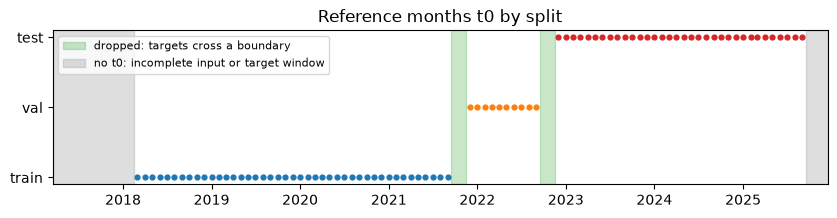

In [19]:
times = cube.indexes["time"]
colours = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
half = pd.Timedelta(days=15)

fig, ax = plt.subplots(figsize=(10, 2))
for split, g in samples.groupby("split", sort=False):
    ax.scatter(g.t0, [split] * len(g), color=colours[split], s=12)

# months between the first and last t0 that were dropped by the split rule
first, last = samples.t0_idx.min(), samples.t0_idx.max()
candidates = times[first : last + 1]
dropped = pd.Series(candidates.difference(samples.t0))
run_id = (dropped.diff() > pd.Timedelta(days=31)).cumsum()
for k, run in dropped.groupby(run_id):
    ax.axvspan(run.iloc[0] - half, run.iloc[-1] + half,
               color="tab:green", alpha=0.25,
               label="dropped: targets cross a boundary" if k == 0 else None)

# edges: no full input window at the start, no full target window at the end
ax.axvspan(times[0] - half, times[first - 1] + half, color="tab:gray", alpha=0.25,
           label="no t0: incomplete input or target window")
ax.axvspan(times[last + 1] - half, times[-1] + half, color="tab:gray", alpha=0.25)

ax.set_xlim(times[0] - half, times[-1] + half)
ax.set_title("Reference months t0 by split")
ax.legend(loc="upper left", fontsize=8)
plt.show()


Each dot represents one sample along the available data time, with a color indicating which split it is assigned to. In green we mark the samples dropped because their targets would fall in two splits, and in grey those that lack enough previous months or target window.


## 3. Land mask

See which pixels are masked as land and thus can be fed to the model. We exclude, on the one hand, water and buil-up surfaces (such as roads or buildings), since their NDVI signals do not reflect any climate-driven variable. And, on the other one, these pixels that have never been observed and thus are not present in the satellite data (due to clouds, etc).

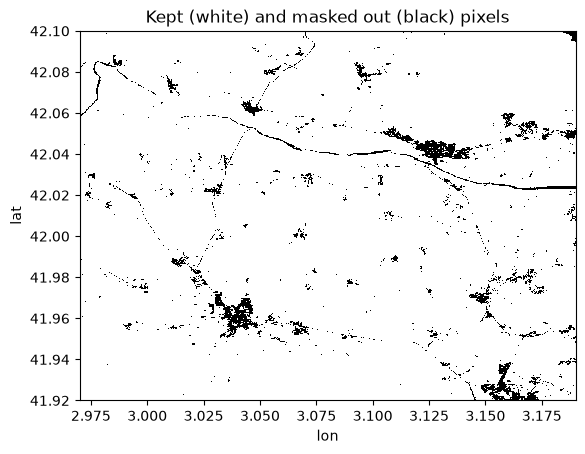

Percentage of pixels kept: 96.3%


In [15]:
land = land_mask(cube)
land.plot(cmap="Greys_r", add_colorbar = False)
plt.title("Kept (white) and masked out (black) pixels")
plt.show()

print(f"Percentage of pixels kept: {float(land.mean()):.1%}")